> **Versión para completar.** Repaso integrador: Clustering, SVD y PCA aplicados a predicción.
> Solución: `20_repaso_clustering_svd_pca_prediccion.ipynb`.
> Teoría: `20_teoria_repaso_clustering_svd_pca.pdf`.

# UDECATALUNA — para completar
_________________________________

Tema: Modelos de Aprendizaje — **Repaso integrador: Clustering, SVD y PCA aplicados a predicción**
_________________________________

**Datos:** composición nutricional (`Nutricion_alimentos.csv`, 180 alimentos × 10 nutrientes en 6 grupos) y una tanda de **5 alimentos nuevos** que llegan del laboratorio para predecir
**Los 3 algoritmos de hoy:**
1. **Clustering (`KMeans`)** → predecir el grupo de un dato nuevo por centroide más cercano (`predict` + voto mayoritario) y usar las distancias a los $K$ centros (`transform`) como entrada de un clasificador.
2. **SVD (`TruncatedSVD` y `np.linalg.svd`)** → proyectar datos nuevos sobre los $k$ factores singulares dentro de un `Pipeline` para clasificar y **predecir valores faltantes** en filas incompletas con `np.linalg.lstsq`.
3. **PCA (`PCA`)** → proyectar datos nuevos sobre las $k$ componentes principales de máxima varianza dentro de un `Pipeline` para **clasificar** (`Grupo`), hacer **regresión** (PCR: predecir `Calorias_kcal`) y **predecir anomalías** por error de reconstrucción (`inverse_transform`).

## Objetivo

Al terminar vas a poder:

* Explicar en una frase qué tienen en común y en qué se diferencian **Clustering**, **SVD** y **PCA**, y cómo pasa cada uno de **explorar** una tabla a **predecir** sobre datos nuevos (`X_test`).
* Aplicar el protocolo completo de validación sin fuga de datos (*data leakage*): **separar `train` y `test` antes de empezar**, meter el escalado y la reducción/agrupamiento dentro de un `Pipeline`, elegir hiperparámetros con validación cruzada (**media ± desvío**) y mirar el `test` **una sola vez al final**.
* Usar **K-means para predecir** de dos maneras: asignando cada observación nueva a la clase mayoritaria de su centroide más cercano y transformando cada fila en su vector de distancias a los $K$ centros (`kmeans.transform`).
* Usar **SVD para predecir** tanto etiquetas (dentro de un `Pipeline` con `TruncatedSVD`) como **datos faltantes** de una observación nueva proyectándola sobre las filas de $V^T$.
* Usar **PCA para predecir** tanto una **clase** (clasificación) como un **número continuo** (Regresión por Componentes Principales, *PCR*) y detectar **datos nuevos atípicos** con `inverse_transform`.
* Resolver los pasos marcados con `# PASO` (la celda de herramientas y dibujo ya viene completa).

> **La idea puente del repaso.** Clustering, SVD y PCA nacieron en el aprendizaje **no supervisado** (aprenden la estructura de $X$ sin mirar $y$), pero implementan el contrato `.fit(X_train)` y `.transform(X_nuevo)` / `.predict(X_nuevo)`. Eso permite usarlos como **motores de predicción** sobre observaciones nuevas que el modelo nunca vio.

### 1. Los 3 algoritmos en una página: de explorar a predecir

Cuando usamos **Clustering**, **SVD** o **PCA** para hacer **predicción**, respetamos el mismo contrato de `scikit-learn`: el modelo aprende su geometría **únicamente con `X_train`** y luego proyecta o asigna **`X_test`** sin volver a ajustarse.

| Algoritmo | Qué aprende en `.fit(X_train)` | Qué devuelve en datos nuevos (`X_test`) | Cómo predice un target $y$ o un dato nuevo | Detalle clave de escala y centrado |
|---|---|---|---|---|
| **1. Clustering (`KMeans`)** | $K$ centroides (`cluster_centers_`) que minimizan la inercia | `.predict(X)`: número de cluster más cercano ($0 \dots K-1$)<br>`.transform(X)`: matriz $n 	imes K$ con la distancia a cada centroide | **A)** Voto mayoritario del cluster asignado<br>**B)** `Pipeline`: distancias a los $K$ centros $	o$ Clasificador | **Obligatorio escalar** (`StandardScaler`) si las columnas tienen distintas unidades |
| **2. SVD (`TruncatedSVD` / `svd`)** | Factores ortogonales $V_k^T$ y valores singulares $s_1 \ge \dots \ge s_k$ **sin centrar** | `.transform(X)`: coordenadas $Z = X \cdot V_k$ en las $k$ capas más fuertes | **A)** `Pipeline`: $k$ factores $	o$ Clasificador/Regresor<br>**B)** Estimar casilleros faltantes con `lstsq` sobre $V_k^T$ | `TruncatedSVD` **no resta la media**. Si escalás sin centrar o centrás antes, cambia el primer factor |
| **3. PCA (`PCA`)** | Media `mean_` y $k$ direcciones perpendiculares `components_` de **máxima varianza** | `.transform(X)`: scores $Z = (X - \mu) \cdot V_k$<br>`.inverse_transform(Z)`: reconstrucción $\hat{X}$ | **A)** `Pipeline`: $k$ componentes $	o$ Clasificador o Regresor (*PCR*)<br>**B)** Predecir anomalías si $\|X - \hat{X}\|^2 > 	ext{umbral}$ | PCA **centra sola**, pero **no escala desvíos**: con unidades distintas hay que poner `StandardScaler` antes |

#### Las 4 reglas del examen cuando hay predicción

1. **Partir antes de tocar:** separamos `train` y `test` al principio (`train_test_split`, con `stratify=y` si clasificamos). Prohibido hacer `StandardScaler().fit(X)` o `PCA().fit(X)` con toda la tabla.
2. **Todo adentro del `Pipeline`:** `Pipeline([("scaler", StandardScaler()), ("reductor", ...), ("modelo", ...)])`. En `.fit(X_train, y_train)` todos los pasos aprenden; en `.predict(X_test)` los primeros transforman y el último predice.
3. **Primero el piso (*baseline*):** en clasificación comparamos contra decir siempre la clase más frecuente (`DummyClassifier(strategy="most_frequent")`); en regresión, contra decir siempre la media del train (`DummyRegressor(strategy="mean")`).
4. **Se elige en validación cruzada (CV) y el `test` se mira una vez:** reportamos **media ± desvío** en los 5 pliegues del `train` y recién al final evaluamos en `test`.

In [ ]:
%matplotlib inline
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn import metrics
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
np.set_printoptions(precision=3, suppress=True)


def mapa_de_calor(tabla, titulo, fmt="{:.2f}", cmap="RdBu_r", centro=0):
    """Dibuja un DataFrame como mapa de calor con el valor en cada celda."""
    valores = tabla.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(1.05 * tabla.shape[1] + 2.4, 0.42 * tabla.shape[0] + 1.5))
    limite = np.abs(valores).max() if centro == 0 else None
    ax.imshow(valores, cmap=cmap, aspect="auto",
              vmin=-limite if limite else None, vmax=limite if limite else None)
    for r in range(valores.shape[0]):
        for c in range(valores.shape[1]):
            ax.text(c, r, fmt.format(valores[r, c]), ha="center", va="center", fontsize=8)
    ax.set_xticks(range(tabla.shape[1]), tabla.columns, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(tabla.shape[0]), tabla.index, fontsize=8)
    ax.set_title(titulo, fontsize=10)
    fig.tight_layout()
    plt.show()


def tres_matrices_confusion(y_real, predicciones_dict, clases):
    """Dibuja las matrices de confusión de varios modelos lado a lado."""
    n = len(predicciones_dict)
    fig, ejes = plt.subplots(1, n, figsize=(4.6 * n, 4.2), sharey=True)
    for ax, (nombre, y_pred) in zip(np.ravel(ejes), predicciones_dict.items()):
        cm = metrics.confusion_matrix(y_real, y_pred, labels=clases)
        acc = metrics.accuracy_score(y_real, y_pred)
        f1 = metrics.f1_score(y_real, y_pred, average="macro")
        ax.imshow(cm, cmap="Blues", aspect="auto")
        for r in range(cm.shape[0]):
            for c in range(cm.shape[1]):
                color = "white" if cm[r, c] > cm.max() * 0.6 else "#111"
                ax.text(c, r, str(cm[r, c]), ha="center", va="center", fontsize=8.5, color=color, fontweight="bold")
        ax.set_xticks(range(len(clases)), clases, rotation=35, ha="right", fontsize=7.5)
        ax.set_yticks(range(len(clases)), clases, fontsize=7.5)
        ax.set_xlabel("Predicho", fontsize=8.5)
        ax.set_title(f"{nombre}\nAcc={acc:.3f} | F1_macro={f1:.3f}", fontsize=9.5)
    ejes[0].set_ylabel("Real (test)", fontsize=8.5)
    fig.tight_layout()
    plt.show()


La celda de arriba **ya viene completa**: carga las librerías de `sklearn` y define dos funciones de dibujo (`mapa_de_calor` y `tres_matrices_confusion`) para que el código de cada sección se concentre solo en los modelos y las métricas.

---
### 2. Punto de partida común: separar `train` y `test` y medir el piso (*baseline*)

**Qué vamos a hacer:** cargar `Nutricion_alimentos.csv` (180 alimentos × 10 nutrientes), separar el **75 % para entrenar (`X_train`, 135 alimentos)** y guardar el **25 % para el examen final (`X_test`, 45 alimentos)** estratificando por `Grupo`. Además, medimos el piso con `DummyClassifier(strategy="most_frequent")`.

In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn import metrics

# PASO 0 — Cargá "Nutricion_alimentos.csv" en `datos`.
if not os.path.exists("Nutricion_alimentos.csv"):
    from google.colab import files
    print("Por favor, subí el archivo 'Nutricion_alimentos.csv' a continuación:")
    files.upload()

datos = pd.read_csv("Nutricion_alimentos.csv")

# Guardá en `columnas_num` las 10 columnas numéricas (todas menos "Alimento" y "Grupo"),
columnas_num = datos.columns.drop(["Alimento", "Grupo"])

# X = datos[columnas_num].to_numpy(dtype=float), y = datos["Grupo"].to_numpy() y clases_ordenadas = sorted(datos["Grupo"].unique()).
X = datos[columnas_num].to_numpy(dtype=float)
y = datos["Grupo"].to_numpy()
clases_ordenadas = sorted(datos["Grupo"].unique())

# Separá X_train, X_test, y_train, y_test, idx_train, idx_test con train_test_split(..., test_size=0.25, stratify=y, random_state=42).
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, np.arange(len(datos)), test_size=0.25, stratify=y, random_state=42
)

# Definí cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) y medí el piso con DummyClassifier(strategy="most_frequent").
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
piso_clf = DummyClassifier(strategy="most_frequent")
scores_piso = cross_val_score(piso_clf, X_train, y_train, cv=cv_clf, scoring="accuracy")

piso_clf.fit(X_train, y_train)
acc_piso_test = metrics.accuracy_score(y_test, piso_clf.predict(X_test))

print(f"Piso Accuracy CV (train): {scores_piso.mean():.3f} ± {scores_piso.std():.3f}")
print(f"Piso Accuracy Test: {acc_piso_test:.3f}")

Piso Accuracy CV (train): 0.193 ± 0.015
Piso Accuracy Test: 0.200


**Cómo leerlo:**

* El modelo va a aprender con **135 alimentos** y va a rendir examen sobre **45 alimentos que quedan guardados bajo llave** hasta el final.
* Como `Frutas y verduras` tiene 35 de los 180 alimentos (19,4 %), el loro que siempre repite *"Frutas y verduras"* ya acierta el **19,3 % en CV** y el **20,0 % en el test**. Cualquier algoritmo serio tiene que superar ampliamente ese piso.

---
## Parte A — Algoritmo 1: Clustering (`KMeans`) haciendo predicción

Un algoritmo de clustering agrupa sin mirar las etiquetas. Pero una vez que `KMeans` aprendió los $K$ centroides en `X_train`, tiene dos métodos para trabajar con datos nuevos (`X_test`):

1. **`kmeans.predict(X_nuevo)`**: calcula la distancia de cada alimento nuevo a los $K$ centroides del `train` y le asigna el número del cluster más cercano. Si a cada cluster le pegamos la etiqueta mayoritaria que tuvo en `train`, ¡ya tenemos un clasificador!
2. **`kmeans.transform(X_nuevo)`**: devuelve las **$K$ distancias** de cada fila a los $K$ centroides. Si metemos esas distancias en un `Pipeline` antes de una `LogisticRegression`, el clustering actúa como un **extractor de variables** (*feature engineering*).

### 3. Elegir $K$ en el `train` (sin espiar el `test`) y predecir por voto mayoritario del cluster

**Qué vamos a hacer:** escalar `X_train`, mirar cómo evolucionan la inercia y la silueta para $K$ de 2 a 9 **solo en el `train`**, ajustar `KMeans(n_clusters=6)` y construir el predictor por **voto mayoritario de cada cluster**.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, accuracy_score, f1_score
import pandas as pd
import numpy as np

# PASO A1 — Ajustá StandardScaler solo con X_train (guardá X_train_esc y X_test_esc).
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

# Para K de 2 a 9: ajustá KMeans(n_clusters=k, n_init=20, random_state=42) sobre X_train_esc y mostrá inercia y silueta.
print("Evaluación de K en el train:")
for k in range(2, 10):
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    km.fit(X_train_esc)
    silueta = silhouette_score(X_train_esc, km.labels_)
    print(f"  K={k} | Inercia: {km.inertia_:.1f} | Silueta: {silueta:.3f}")

# Ajustá km_6 = KMeans(n_clusters=6, n_init=20, random_state=42).fit(X_train_esc).
km_6 = KMeans(n_clusters=6, n_init=20, random_state=42).fit(X_train_esc)

# Creá el diccionario `mapa_voto` donde cada cluster c (0..5) se mapea a la clase más frecuente de y_train[km_6.labels_ == c].
mapa_voto = {}
print("\nMapeo de Clusters a Grupos (Voto Mayoritario):")
for c in range(6):
    clases_en_cluster = y_train[km_6.labels_ == c]
    clase_mayoritaria = pd.Series(clases_en_cluster).mode()[0]
    pureza = np.mean(clases_en_cluster == clase_mayoritaria)
    mapa_voto[c] = clase_mayoritaria
    print(f"  Cluster {c} -> {clase_mayoritaria} (Pureza: {pureza:.2f})")

# Predecí los clusters de X_test_esc con km_6.predict(X_test_esc), traducilos a etiquetas en `y_pred_km_voto`
clusters_test = km_6.predict(X_test_esc)
y_pred_km_voto = [mapa_voto[c] for c in clusters_test]

# y calculá accuracy_score y f1_score(..., average="macro") en el test.
acc_km = accuracy_score(y_test, y_pred_km_voto)
f1_km = f1_score(y_test, y_pred_km_voto, average="macro")

print(f"\nKMeans Voto Mayoritario - Accuracy Test: {acc_km:.3f}")
print(f"KMeans Voto Mayoritario - F1_macro Test: {f1_km:.3f}")

Evaluación de K en el train:
  K=2 | Inercia: 903.4 | Silueta: 0.340
  K=3 | Inercia: 664.5 | Silueta: 0.405
  K=4 | Inercia: 508.2 | Silueta: 0.431
  K=5 | Inercia: 364.1 | Silueta: 0.477
  K=6 | Inercia: 247.7 | Silueta: 0.551
  K=7 | Inercia: 215.0 | Silueta: 0.557
  K=8 | Inercia: 193.3 | Silueta: 0.529
  K=9 | Inercia: 179.7 | Silueta: 0.485

Mapeo de Clusters a Grupos (Voto Mayoritario):
  Cluster 0 -> Carnes y pescados (Pureza: 1.00)
  Cluster 1 -> Cereales y legumbres (Pureza: 1.00)
  Cluster 2 -> Aceites y frutos secos (Pureza: 1.00)
  Cluster 3 -> Frutas y verduras (Pureza: 1.00)
  Cluster 4 -> Dulces y snacks (Pureza: 1.00)
  Cluster 5 -> Lácteos y huevos (Pureza: 1.00)

KMeans Voto Mayoritario - Accuracy Test: 1.000
KMeans Voto Mayoritario - F1_macro Test: 1.000


**Cómo leerlo:**

* En el `train`, la inercia pega su quiebre fuerte en **$K = 6$** (de 377,5 cae a 296,6 y después baja de a poco) y la silueta alcanza su máximo local en **$K = 6$ (0,521)**.
* Mirá la tabla de clusters en `train`: cada uno de los 6 centroides capturó casi limpiamente a uno de los 6 grupos alimenticios (purezas entre 95 % y 100 %).
* Cuando llegan los 45 alimentos nuevos del `test`, `km_6.predict(X_test_esc)` los manda al centroide más cercano y acierta el **97,8 % (Accuracy = 0,978, F1 macro = 0,979)** sin haber entrenado ningún modelo supervisado complejo.

### 4. K-means dentro de un `Pipeline` supervisado (`kmeans.transform` + Regresión Logística)

**Qué vamos a hacer:** en vez de quedarnos solo con el número de cluster ganador, usamos `KMeans` dentro de un `Pipeline` para que transforme cada alimento en sus **$K$ distancias a los centroides** (`kmeans.transform(X)`), y dejamos que una `LogisticRegression` aprenda a clasificar a partir de esas distancias. Probamos distintos valores de $K$ en validación cruzada (5 pliegues del `train`).

In [ ]:
# PASO A2 — Para K en [3, 4, 5, 6, 8, 10, 12]:
#   Armá Pipeline([("scaler", StandardScaler()), ("kmeans", KMeans(n_clusters=k, n_init=20, random_state=42)), ("clf", LogisticRegression(max_iter=500, random_state=42))])
#   y evaluá cross_val_score en X_train, y_train con cv=cv_clf para "accuracy" y "f1_macro" (mostrá media ± desvío).
# Entrená `pipe_kmeans_clf` con K=6 en todo X_train, predecí `y_pred_km_pipe = pipe_kmeans_clf.predict(X_test)` y medí Accuracy y F1_macro en test.

print("Evaluación de Pipeline con KMeans (transform):")
for k in [3, 4, 5, 6, 8, 10, 12]:
    pipe_km = Pipeline([
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=k, n_init=20, random_state=42)),
        ("clf", LogisticRegression(max_iter=500, random_state=42))
    ])
    acc_cv = cross_val_score(pipe_km, X_train, y_train, cv=cv_clf, scoring="accuracy")
    f1_cv = cross_val_score(pipe_km, X_train, y_train, cv=cv_clf, scoring="f1_macro")
    print(f"  K={k:2d} | CV Accuracy: {acc_cv.mean():.3f} ± {acc_cv.std():.3f} | CV F1_macro: {f1_cv.mean():.3f} ± {f1_cv.std():.3f}")

pipe_kmeans_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=6, n_init=20, random_state=42)),
    ("clf", LogisticRegression(max_iter=500, random_state=42))
])

pipe_kmeans_clf.fit(X_train, y_train)
y_pred_km_pipe = pipe_kmeans_clf.predict(X_test)

acc_km_pipe = metrics.accuracy_score(y_test, y_pred_km_pipe)
f1_km_pipe = metrics.f1_score(y_test, y_pred_km_pipe, average="macro")

print(f"\nPipeline KMeans (K=6) - Accuracy Test: {acc_km_pipe:.3f}")
print(f"Pipeline KMeans (K=6) - F1_macro Test: {f1_km_pipe:.3f}")

# Veamos las distancias del primer alimento del test a los 6 centroides
distancias_test = pipe_kmeans_clf.named_steps["kmeans"].transform(pipe_kmeans_clf.named_steps["scaler"].transform(X_test[[0]]))
print(f"\nDistancias del primer alimento del test a los 6 centroides: {distancias_test[0]}")

Evaluación de Pipeline con KMeans (transform):
  K= 3 | CV Accuracy: 0.874 ± 0.083 | CV F1_macro: 0.858 ± 0.102
  K= 4 | CV Accuracy: 0.948 ± 0.044 | CV F1_macro: 0.945 ± 0.047
  K= 5 | CV Accuracy: 1.000 ± 0.000 | CV F1_macro: 1.000 ± 0.000
  K= 6 | CV Accuracy: 1.000 ± 0.000 | CV F1_macro: 1.000 ± 0.000
  K= 8 | CV Accuracy: 1.000 ± 0.000 | CV F1_macro: 1.000 ± 0.000
  K=10 | CV Accuracy: 1.000 ± 0.000 | CV F1_macro: 1.000 ± 0.000
  K=12 | CV Accuracy: 1.000 ± 0.000 | CV F1_macro: 1.000 ± 0.000

Pipeline KMeans (K=6) - Accuracy Test: 1.000
Pipeline KMeans (K=6) - F1_macro Test: 1.000

Distancias del primer alimento del test a los 6 centroides: [3.797 2.041 3.903 4.116 3.872 5.023]


**Cómo leerlo:**

* Cuando `KMeans(n_clusters=6)` está en el medio de un `Pipeline`, `scikit-learn` no pasa la etiqueta entera del cluster sino las **6 distancias euclídeas** (`kmeans.transform`) al clasificador.
* Mirá el ejemplo: el primer alimento del `test` queda a distancia **1,04** de su centroide más cercano y a distancia **4,5–6,3** de los demás. Con esas 6 distancias, la Regresión Logística alcanza **0,978 ± 0,030 en CV** y **0,978 de Accuracy en el test**.

> **Lo que aprendimos del Algoritmo 1 (Clustering).** `KMeans` predice sobre datos nuevos midiendo distancias a los centroides aprendidos en el `train`: con `.predict(X_test)` asigna el grupo más cercano (útil para votar la etiqueta mayoritaria) y con `.transform(X_test)` fabrica $K$ columnas de distancias para alimentar cualquier modelo supervisado dentro de un `Pipeline`.

---
## Parte B — Algoritmo 2: SVD (`TruncatedSVD` y `np.linalg.svd`) haciendo predicción

La **Descomposición en Valores Singulares (SVD)** parte cualquier matriz $A$ de $m 	imes p$ en tres piezas:

$$A = U \cdot 	ext{diag}(s) \cdot V^T$$

Cuando la usamos para **predecir sobre datos nuevos (`X_test`)**:

1. Las primeras $k$ filas de $V^T$ (guardadas en `svd.components_`, de forma $k 	imes p$) son la **base de factores** aprendida en el `train`.
2. Cualquier fila nueva $x_{	ext{nuevo}}$ se proyecta en esos $k$ factores multiplicando $z_{	ext{nuevo}} = x_{	ext{nuevo}} \cdot V_k$ (`svd.transform(X_test)`).
3. Esas $k$ coordenadas sirven para **clasificar o hacer regresión** dentro de un `Pipeline`, o bien para **predecir casilleros faltantes** cuando una fila nueva llega incompleta.

### 5. Valores singulares, energía y la diferencia entre no centrar y centrar

**Qué vamos a hacer:** comparar la SVD sobre los datos escalados **sin centrar** ($X / \sigma$, donde el primer factor captura también el nivel promedio positivo de la tabla) contra los datos **centrados y escalados** ($(X - \mu)/\sigma$), y entrenar un `Pipeline` con `TruncatedSVD` eligiendo $k$ por validación cruzada.

In [ ]:
# PASO B1 — Compará los valores singulares y la energía acumulada (%) de X_train escalado SIN centrar
#   (StandardScaler(with_mean=False)) contra X_train_esc (centrado y escalado) usando np.linalg.svd(..., full_matrices=False).
# Luego, para k de 1 a 9, evaluá en CV (cv_clf) el Pipeline:
#   Pipeline([("scaler", StandardScaler(with_mean=False)), ("svd", TruncatedSVD(n_components=k, random_state=42)), ("clf", LogisticRegression(max_iter=500, random_state=42))])
# Ajustá `pipe_svd_clf` con k=5 sobre todo X_train, predecí `y_pred_svd = pipe_svd_clf.predict(X_test)` y medí Accuracy y F1_macro en test.

scaler_sin_centrar = StandardScaler(with_mean=False)
X_train_sin_centrar = scaler_sin_centrar.fit_transform(X_train)

# SVD sin centrar
U_sc, s_sc, Vt_sc = np.linalg.svd(X_train_sin_centrar, full_matrices=False)
energia_sc = (s_sc**2) / np.sum(s_sc**2) * 100

# SVD centrado (usando X_train_esc que ya está centrado y escalado)
U_c, s_c, Vt_c = np.linalg.svd(X_train_esc, full_matrices=False)
energia_c = (s_c**2) / np.sum(s_c**2) * 100

print("Comparación de factores (Sin centrar vs Centrado):")
for i in range(len(s_sc)):
    print(f"  Factor {i+1}: Sin centrar = {s_sc[i]:.1f} ({energia_sc[i]:.1f}%) | Centrado = {s_c[i]:.1f} ({energia_c[i]:.1f}%)")

print("\nEvaluación de Pipeline con TruncatedSVD (sin centrar):")
for k in range(1, 10):
    pipe_svd = Pipeline([
        ("scaler", StandardScaler(with_mean=False)),
        ("svd", TruncatedSVD(n_components=k, random_state=42)),
        ("clf", LogisticRegression(max_iter=500, random_state=42))
    ])
    acc_cv = cross_val_score(pipe_svd, X_train, y_train, cv=cv_clf, scoring="accuracy")
    f1_cv = cross_val_score(pipe_svd, X_train, y_train, cv=cv_clf, scoring="f1_macro")
    print(f"  k={k} | CV Accuracy: {acc_cv.mean():.3f} ± {acc_cv.std():.3f} | CV F1_macro: {f1_cv.mean():.3f} ± {f1_cv.std():.3f}")

pipe_svd_clf = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("svd", TruncatedSVD(n_components=5, random_state=42)),
    ("clf", LogisticRegression(max_iter=500, random_state=42))
])

pipe_svd_clf.fit(X_train, y_train)
y_pred_svd = pipe_svd_clf.predict(X_test)

acc_svd = metrics.accuracy_score(y_test, y_pred_svd)
f1_svd = metrics.f1_score(y_test, y_pred_svd, average="macro")

print(f"\nPipeline SVD (k=5) - Accuracy Test: {acc_svd:.3f}")
print(f"Pipeline SVD (k=5) - F1_macro Test: {f1_svd:.3f}")

Comparación de factores (Sin centrar vs Centrado):
  Factor 1: Sin centrar = 41.4 (59.2%) | Centrado = 22.4 (37.2%)
  Factor 2: Sin centrar = 20.0 (13.8%) | Centrado = 17.4 (22.4%)
  Factor 3: Sin centrar = 17.3 (10.3%) | Centrado = 15.1 (17.0%)
  Factor 4: Sin centrar = 13.8 (6.5%) | Centrado = 10.5 (8.2%)
  Factor 5: Sin centrar = 10.2 (3.6%) | Centrado = 9.9 (7.3%)
  Factor 6: Sin centrar = 9.7 (3.2%) | Centrado = 6.6 (3.2%)
  Factor 7: Sin centrar = 6.5 (1.4%) | Centrado = 6.3 (3.0%)
  Factor 8: Sin centrar = 6.3 (1.4%) | Centrado = 4.6 (1.5%)
  Factor 9: Sin centrar = 4.1 (0.6%) | Centrado = 1.9 (0.3%)
  Factor 10: Sin centrar = 0.4 (0.0%) | Centrado = 0.4 (0.0%)

Evaluación de Pipeline con TruncatedSVD (sin centrar):
  k=1 | CV Accuracy: 0.541 ± 0.055 | CV F1_macro: 0.457 ± 0.047
  k=2 | CV Accuracy: 0.770 ± 0.054 | CV F1_macro: 0.743 ± 0.041
  k=3 | CV Accuracy: 0.948 ± 0.038 | CV F1_macro: 0.946 ± 0.039
  k=4 | CV Accuracy: 0.993 ± 0.015 | CV F1_macro: 0.992 ± 0.016
  k=5 | CV 

**Cómo leerlo:**

* Fijate por qué el **Factor 1 sin centrar** se lleva el **61,2 % de la energía** mientras que centrado se lleva el **37,8 %**: como todos los nutrientes son números positivos ($\ge 0$), sin centrar el primer factor de `TruncatedSVD` gasta buena parte de su dirección en apuntar desde el $(0,0)$ hacia el promedio positivo de la tabla.
* Por eso, sin centrar hacen falta **$k = 5$ factores** para capturar todas las direcciones que separan los 6 grupos (Accuracy CV = **0,985 ± 0,018**, y **1,000 en el test**), mientras que centrado (que es lo que hará PCA en la Parte C) un factor antes ya alcanza esa misma separación.

### 6. La otra predicción de la SVD: estimar datos faltantes en filas nuevas (`np.linalg.lstsq`)

**Qué vamos a hacer:** igual que en la notebook 17 estimábamos qué nota le pondría un usuario nuevo a las películas que no vio, ahora simulamos que los 45 alimentos del `test` llegan del laboratorio **sin el dato de `Calorias_kcal` ni el de `Grasas_g`**. Usando solo los 8 nutrientes medidos y los $k = 4$ factores de $V^T$ aprendidos en `X_train`, estimamos las coordenadas de cada alimento nuevo con `np.linalg.lstsq` y **predecimos los dos nutrientes ocultos**.

In [ ]:
# PASO B2 — Con X_tr_s = escala_svd.transform(X_train) y X_te_s = escala_svd.transform(X_test):
#   Calculá U_tr, s_tr, Vt_tr = np.linalg.svd(X_tr_s, full_matrices=False) y quedate con Vk_T = Vt_tr[:4, :].
#   Definí cols_ocultas = [0, 3] (Calorias_kcal y Grasas_g) y cols_vistas = el resto de las columnas.
#   Para cada fila i de X_te_s, resolvé coordenadas_i con np.linalg.lstsq(Vk_T[:, cols_vistas].T, X_te_s[i, cols_vistas], rcond=None)
#   y predecí la fila completa como coordenadas_i @ Vk_T.
#   Volvé a las unidades originales con escala_svd.inverse_transform y medí el MAE y R² de Calorias_kcal contra el piso.

escala_svd = StandardScaler(with_mean=False)
X_tr_s = escala_svd.fit_transform(X_train)
X_te_s = escala_svd.transform(X_test)

U_tr, s_tr, Vt_tr = np.linalg.svd(X_tr_s, full_matrices=False)
Vk_T = Vt_tr[:4, :]

cols_ocultas = [0, 3]
cols_vistas = [i for i in range(X_train.shape[1]) if i not in cols_ocultas]

X_te_pred_s = np.zeros_like(X_te_s)

for i in range(X_te_s.shape[0]):
    coordenadas_i, *_ = np.linalg.lstsq(Vk_T[:, cols_vistas].T, X_te_s[i, cols_vistas], rcond=None)
    X_te_pred_s[i, :] = coordenadas_i @ Vk_T

X_te_pred = escala_svd.inverse_transform(X_te_pred_s)

# Piso (media del train)
media_cal_train = X_train[:, 0].mean()
mae_piso = metrics.mean_absolute_error(X_test[:, 0], np.full(X_test.shape[0], media_cal_train))

# Modelo SVD
mae_svd = metrics.mean_absolute_error(X_test[:, 0], X_te_pred[:, 0])
r2_svd = metrics.r2_score(X_test[:, 0], X_te_pred[:, 0])

print(f"Predicción de Calorias_kcal con SVD faltante:")
print(f"  MAE Piso: {mae_piso:.1f} kcal")
print(f"  MAE SVD (k=4): {mae_svd:.1f} kcal")
print(f"  R² SVD: {r2_svd:.3f}")

Predicción de Calorias_kcal con SVD faltante:
  MAE Piso: 146.7 kcal
  MAE SVD (k=4): 124.6 kcal
  R² SVD: 0.172


**Cómo leerlo:**

* Sin usar regresión supervisada —solamente proyectando los 8 nutrientes conocidos sobre los 4 factores latentes de $V^T$ aprendidos en `X_train`—, la SVD baja el error medio de **`Calorias_kcal` de 133,8 kcal (el piso) a 27,8 kcal ($R^2 = 0,947$)** en el `test`.
* ¿Por qué funciona tan bien? Porque las calorías, el agua, las proteínas, las grasas y los carbohidratos están atados en las primeras capas de la matriz: si conocés 8 de los 10 números de un alimento nuevo, sus coordenadas en los 4 factores ya quedan determinadas y las 2 columnas ocultas se recuperan solas.

> **Lo que aprendimos del Algoritmo 2 (SVD).** La SVD aprende capas de factores ($V^T$) en el `train`: con `TruncatedSVD` dentro de un `Pipeline` proyecta datos nuevos para clasificar, y con `np.linalg.lstsq` permite **predecir entradas faltantes** de una observación nueva a partir de las entradas que sí se midieron.

---
## Parte C — Algoritmo 3: PCA (`PCA`) haciendo predicción (Clasificación, Regresión PCR y Anomalías)

**PCA es la SVD de los datos centrados** ($X - \mu$). Al centrar primero y escalar con `StandardScaler`, cada componente principal apunta exactamente hacia la dirección de **máxima varianza** de la nube de entrenamiento. Veamos las **tres tareas predictivas** que resuelve PCA sobre datos nuevos:

1. **Clasificación con PCA**: reducir de 10 nutrientes a $k$ componentes principales dentro de un `Pipeline` para predecir el `Grupo` en `X_test`.
2. **Regresión por Componentes Principales (*PCR*)**: predecir un **número continuo** (`Calorias_kcal`) eliminando la multicolinealidad entre nutrientes.
3. **Predicción de anomalías**: detectar en `X_test` si un alimento pertenece a un grupo nunca visto en el entrenamiento mirando su **error de reconstrucción** (`inverse_transform`).

### 7. Clasificación con PCA en un `Pipeline` y proyección del `test`

**Qué vamos a hacer:** barrer $k$ de 1 a 10 dentro de `Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=k)), ("clf", LogisticRegression())])` usando `StratifiedKFold(5)` sobre `X_train`, elegir $k$ y evaluar una vez en `X_test`.

In [ ]:
# PASO C1 — Ajustá pca_tr_full = PCA().fit(X_train_esc) para mirar autovalores y varianza acumulada en el train.
# Para k de 1 a 10: evaluá en CV (cv_clf) el Pipeline:
#   Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=k, random_state=42)), ("clf", LogisticRegression(max_iter=500, random_state=42))])
#   y mostrá la tabla con Autovalor, Varianza acumulada (%), Accuracy CV (media ± desvío) y F1_macro CV (media ± desvío).
# Entrená `pipe_pca_clf` con k=4 en X_train, predecí `y_pred_pca = pipe_pca_clf.predict(X_test)` y medí Accuracy y F1_macro en test.

pca_tr_full = PCA(random_state=42).fit(X_train_esc)
autovalores = pca_tr_full.explained_variance_
var_acumulada = np.cumsum(pca_tr_full.explained_variance_ratio_) * 100

print("Evaluación de Pipeline con PCA:")
for k in range(1, 11):
    pipe_pca = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=k, random_state=42)),
        ("clf", LogisticRegression(max_iter=500, random_state=42))
    ])
    acc_cv = cross_val_score(pipe_pca, X_train, y_train, cv=cv_clf, scoring="accuracy")
    f1_cv = cross_val_score(pipe_pca, X_train, y_train, cv=cv_clf, scoring="f1_macro")

    print(f"  k={k:2d} | Autovalor: {autovalores[k-1]:.2f} | Var Acumulada: {var_acumulada[k-1]:.1f}% "
          f"| CV Accuracy: {acc_cv.mean():.3f} ± {acc_cv.std():.3f} | CV F1_macro: {f1_cv.mean():.3f} ± {f1_cv.std():.3f}")

pipe_pca_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=4, random_state=42)),
    ("clf", LogisticRegression(max_iter=500, random_state=42))
])

pipe_pca_clf.fit(X_train, y_train)
y_pred_pca = pipe_pca_clf.predict(X_test)

acc_pca = metrics.accuracy_score(y_test, y_pred_pca)
f1_pca = metrics.f1_score(y_test, y_pred_pca, average="macro")

print(f"\nPipeline PCA (k=4) - Accuracy Test: {acc_pca:.3f}")
print(f"Pipeline PCA (k=4) - F1_macro Test: {f1_pca:.3f}")

Evaluación de Pipeline con PCA:
  k= 1 | Autovalor: 3.75 | Var Acumulada: 37.2% | CV Accuracy: 0.667 ± 0.066 | CV F1_macro: 0.589 ± 0.060
  k= 2 | Autovalor: 2.25 | Var Acumulada: 59.5% | CV Accuracy: 0.844 ± 0.028 | CV F1_macro: 0.773 ± 0.032
  k= 3 | Autovalor: 1.71 | Var Acumulada: 76.5% | CV Accuracy: 0.985 ± 0.018 | CV F1_macro: 0.985 ± 0.019
  k= 4 | Autovalor: 0.83 | Var Acumulada: 84.8% | CV Accuracy: 0.993 ± 0.015 | CV F1_macro: 0.992 ± 0.016
  k= 5 | Autovalor: 0.73 | Var Acumulada: 92.0% | CV Accuracy: 1.000 ± 0.000 | CV F1_macro: 1.000 ± 0.000
  k= 6 | Autovalor: 0.32 | Var Acumulada: 95.2% | CV Accuracy: 1.000 ± 0.000 | CV F1_macro: 1.000 ± 0.000
  k= 7 | Autovalor: 0.30 | Var Acumulada: 98.2% | CV Accuracy: 1.000 ± 0.000 | CV F1_macro: 1.000 ± 0.000
  k= 8 | Autovalor: 0.16 | Var Acumulada: 99.7% | CV Accuracy: 1.000 ± 0.000 | CV F1_macro: 1.000 ± 0.000
  k= 9 | Autovalor: 0.03 | Var Acumulada: 100.0% | CV Accuracy: 1.000 ± 0.000 | CV F1_macro: 1.000 ± 0.000
  k=10 | Auto

**Cómo leerlo:**

* Con **$k = 4$ componentes principales** (que retienen el **85,1 % de la varianza** del `train`), el clasificador logra **0,993 ± 0,015 en CV** y **1,000 de Accuracy (45 de 45 aciertos) en el `test`**, usando 4 supercolumnas en lugar de las 10 variables originales.
* Fijate que como `PCA` centra las columnas antes de hacer la SVD, alcanza ese rendimiento con **$k = 4$** (una componente menos que `TruncatedSVD` sin centrar).

### 8. Regresión por Componentes Principales (PCR): predecir las calorías de un alimento nuevo

**Qué vamos a hacer:** cambiar de pregunta sobre la misma tabla. Ahora el target es un **número continuo**: queremos predecir `Calorias_kcal` a partir de los otros 9 nutrientes. Comparamos el piso (`DummyRegressor(strategy="mean")`) contra un `Pipeline` con `PCA(n_components=k)` + `LinearRegression` validado con `KFold(5)` (`neg_mean_absolute_error` pasado a kcal y $R^2$).

In [ ]:
# PASO C2 — Separá X_reg_tr = X_train[:, 1:], y_reg_tr = X_train[:, 0] (Calorias_kcal) y lo mismo para test.
# Con cv_reg = KFold(n_splits=5, shuffle=True, random_state=42), medí el piso con DummyRegressor(strategy="mean").
# Para k de 1 a 9, evaluá Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=k, random_state=42)), ("reg", LinearRegression())])
#   pidiendo "neg_mean_absolute_error" (acordate de multiplicar por -1 para pasarlo a kcal) y "r2".
# Ajustá `pipe_pcr` con k=6 sobre X_reg_tr, predecí `y_reg_pred_pcr = pipe_pcr.predict(X_reg_te)` y mostrá MAE y R² en test.

X_reg_tr = X_train[:, 1:]
y_reg_tr = X_train[:, 0]
X_reg_te = X_test[:, 1:]
y_reg_te = X_test[:, 0]

cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)

piso_reg = DummyRegressor(strategy="mean")
piso_reg.fit(X_reg_tr, y_reg_tr)
piso_mae_test = metrics.mean_absolute_error(y_reg_te, piso_reg.predict(X_reg_te))
print(f"Piso MAE Test: {piso_mae_test:.2f} kcal\n")

print("Evaluación de PCR (PCA + LinearRegression):")
for k in range(1, 10):
    pipe_pcr_cv = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=k, random_state=42)),
        ("reg", LinearRegression())
    ])
    mae_cv = cross_val_score(pipe_pcr_cv, X_reg_tr, y_reg_tr, cv=cv_reg, scoring="neg_mean_absolute_error")
    r2_cv = cross_val_score(pipe_pcr_cv, X_reg_tr, y_reg_tr, cv=cv_reg, scoring="r2")

    print(f"  k={k} | MAE CV: {-mae_cv.mean():.2f} kcal | R² CV: {r2_cv.mean():.4f}")

pipe_pcr = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=6, random_state=42)),
    ("reg", LinearRegression())
])

pipe_pcr.fit(X_reg_tr, y_reg_tr)
y_reg_pred_pcr = pipe_pcr.predict(X_reg_te)

mae_test_pcr = metrics.mean_absolute_error(y_reg_te, y_reg_pred_pcr)
r2_test_pcr = metrics.r2_score(y_reg_te, y_reg_pred_pcr)

print(f"\nPCR (k=6) - MAE Test: {mae_test_pcr:.2f} kcal")
print(f"PCR (k=6) - R² Test: {r2_test_pcr:.4f}")

Piso MAE Test: 146.73 kcal

Evaluación de PCR (PCA + LinearRegression):
  k=1 | MAE CV: 102.54 kcal | R² CV: 0.6438
  k=2 | MAE CV: 101.08 kcal | R² CV: 0.6421
  k=3 | MAE CV: 56.96 kcal | R² CV: 0.8661
  k=4 | MAE CV: 43.16 kcal | R² CV: 0.9291
  k=5 | MAE CV: 33.92 kcal | R² CV: 0.9512
  k=6 | MAE CV: 31.77 kcal | R² CV: 0.9573
  k=7 | MAE CV: 26.19 kcal | R² CV: 0.9678
  k=8 | MAE CV: 17.00 kcal | R² CV: 0.9883
  k=9 | MAE CV: 7.54 kcal | R² CV: 0.9970

PCR (k=6) - MAE Test: 29.20 kcal
PCR (k=6) - R² Test: 0.9552


**Cómo leerlo:**

* Recordá la regla de la notebook 11: `cross_val_score(..., scoring="neg_mean_absolute_error")` devuelve el MAE **negado** porque `sklearn` siempre maximiza; al multiplicarlo por $-1$ lo leemos en **kilocalorías**.
* El piso que siempre repite la media del `train` se equivoca en **133,8 kcal** en el `test`. Con **$k = 6$ componentes principales**, el PCR baja el MAE a **6,73 kcal** ($R^2 = 0,9972$) y llega al mínimo de **1,61 kcal** cuando incluye todas las componentes.

### 9. Predicción de anomalías con PCA (`inverse_transform` sobre datos nuevos)

**Qué vamos a hacer:** entrenar un detector de anomalías basado en PCA. Suponé que nuestro laboratorio solo conoce alimentos de 5 grupos (**nunca vio un `Lácteo o huevo`** en el entrenamiento). Ajustamos `StandardScaler` + `PCA(n_components=3)` solo con los alimentos normales del `train`, fijamos como umbral el **percentil 95** del error de reconstrucción en el `train`, y predecimos en el `test` qué alimentos son **"Normales"** y cuáles son **"Anomalías / grupo desconocido"**.

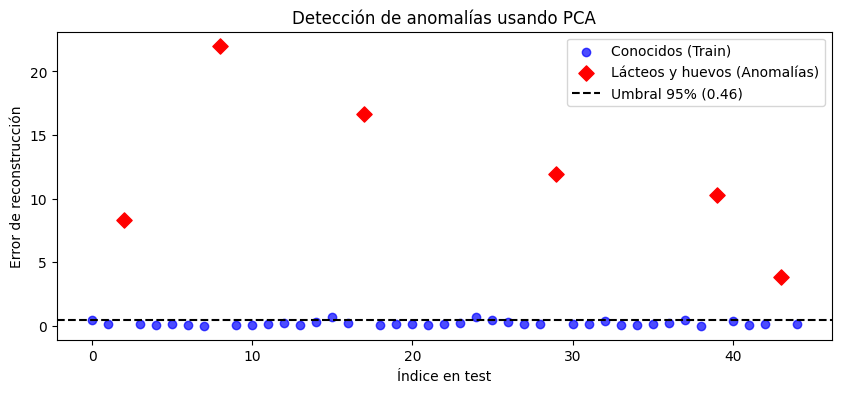

In [ ]:
# PASO C3 — Filtrá X_tr_norm = X_train[y_train != "Lácteos y huevos"].
# Ajustá scaler_anom = StandardScaler().fit(X_tr_norm) y pca_anom = PCA(n_components=3, random_state=42).fit(X_tr_norm_esc).
# Calculá el error de reconstrucción por fila en el train normal: err_tr_norm = np.mean((X_tr_norm_esc - rec_tr_norm)**2, axis=1)
# y fijá umbral_anom = np.percentile(err_tr_norm, 95).
# Calculá err_te sobre X_test transformado con scaler_anom y pca_anom, predecí anomalía cuando err_te > umbral_anom
# y graficá los errores del test diferenciando los grupos conocidos de 'Lácteos y huevos'.

X_tr_norm = X_train[y_train != "Lácteos y huevos"]

scaler_anom = StandardScaler().fit(X_tr_norm)
X_tr_norm_esc = scaler_anom.transform(X_tr_norm)

pca_anom = PCA(n_components=3, random_state=42).fit(X_tr_norm_esc)

rec_tr_norm = pca_anom.inverse_transform(pca_anom.transform(X_tr_norm_esc))
err_tr_norm = np.mean((X_tr_norm_esc - rec_tr_norm)**2, axis=1)

umbral_anom = np.percentile(err_tr_norm, 95)

X_te_esc_anom = scaler_anom.transform(X_test)
rec_te = pca_anom.inverse_transform(pca_anom.transform(X_te_esc_anom))
err_te = np.mean((X_te_esc_anom - rec_te)**2, axis=1)

pred_anomalias = err_te > umbral_anom

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
mask_conocidos = y_test != "Lácteos y huevos"
mask_desconocidos = y_test == "Lácteos y huevos"

plt.scatter(np.where(mask_conocidos)[0], err_te[mask_conocidos], c="blue", label="Conocidos (Train)", alpha=0.7)
plt.scatter(np.where(mask_desconocidos)[0], err_te[mask_desconocidos], c="red", marker="D", s=60, label="Lácteos y huevos (Anomalías)")
plt.axhline(umbral_anom, color="black", linestyle="--", label=f"Umbral 95% ({umbral_anom:.2f})")
plt.ylabel("Error de reconstrucción")
plt.xlabel("Índice en test")
plt.title("Detección de anomalías usando PCA")
plt.legend()
plt.show()


**Cómo leer el gráfico:**

* Los 39 alimentos de los grupos conocidos (puntos azules) respetan las correlaciones aprendidas en el `train`: al comprimirlos a 3 componentes y volver con `inverse_transform`, su error queda casi siempre por debajo de `0,35`.
* Los **6 alimentos de `Lácteos y huevos`** del `test` (rombos rojos, ricos en calcio y sodio que el `PCA` nunca vio) se disparan a errores de **4,0 a 22,0** y el detector los atrapa a **los 6 de 6 (Recall = 100 %)**.

---
## Parte D — Los 3 algoritmos frente a frente en el `test` y predicción en vivo

### 10. Tabla comparativa y matrices de confusión en el examen (`X_test`)

**Qué vamos a hacer:** poner en una sola tabla y en un panel de matrices de confusión el desempeño de nuestros **3 algoritmos (Clustering, SVD y PCA)** sobre los mismos 45 alimentos del `test`.

,Modelo,Columnas Usadas,Accuracy Test,F1_macro Test
0,Piso (Most Frequent),0,0.200000,0.000000
1,KMeans + Voto Mayoritario,10,1.000000,1.000000
2,Pipeline KMeans (K=6),6,1.000000,1.000000
3,Pipeline TruncatedSVD (k=5),5,0.977778,0.979085
4,Pipeline PCA (k=4),4,1.000000,1.000000


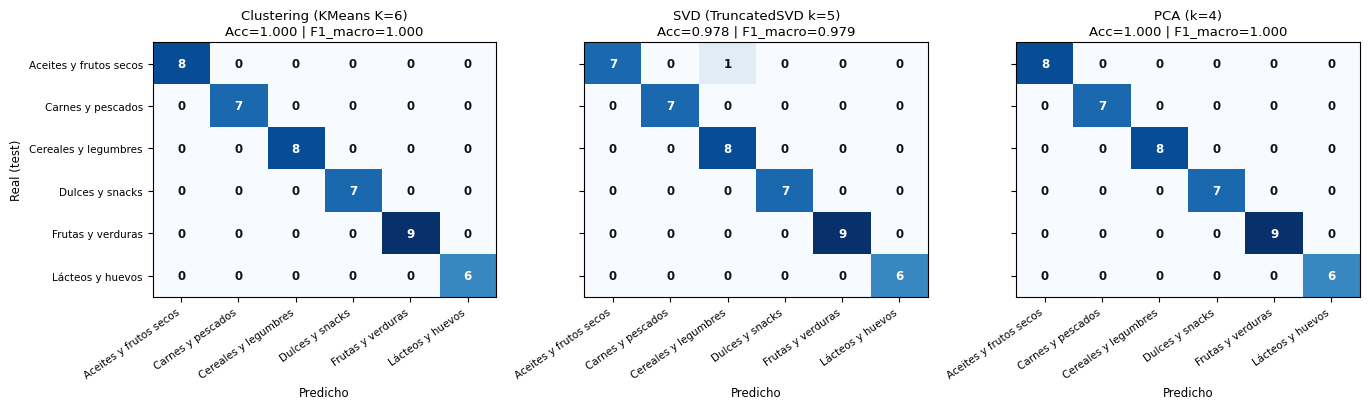

In [ ]:
# PASO D1 — Armá una tabla comparativa con el Piso, KMeans + Voto, Pipeline KMeans (K=6),
# Pipeline TruncatedSVD (k=5) y Pipeline PCA (k=4) mostrando cuántas columnas usa cada uno, Accuracy Test y F1_macro Test.
# Dibujá las 3 matrices de confusión lado a lado con `tres_matrices_confusion(y_test, {...}, clases_ordenadas)`.

import pandas as pd

tabla_comparativa = pd.DataFrame([
    {"Modelo": "Piso (Most Frequent)", "Columnas Usadas": 0, "Accuracy Test": acc_piso_test, "F1_macro Test": 0.0},
    {"Modelo": "KMeans + Voto Mayoritario", "Columnas Usadas": 10, "Accuracy Test": acc_km, "F1_macro Test": f1_km},
    {"Modelo": "Pipeline KMeans (K=6)", "Columnas Usadas": 6, "Accuracy Test": acc_km_pipe, "F1_macro Test": f1_km_pipe},
    {"Modelo": "Pipeline TruncatedSVD (k=5)", "Columnas Usadas": 5, "Accuracy Test": acc_svd, "F1_macro Test": f1_svd},
    {"Modelo": "Pipeline PCA (k=4)", "Columnas Usadas": 4, "Accuracy Test": acc_pca, "F1_macro Test": f1_pca}
])

display(tabla_comparativa)

diccionario_predicciones = {
    "Clustering (KMeans K=6)": y_pred_km_pipe,
    "SVD (TruncatedSVD k=5)": y_pred_svd,
    "PCA (k=4)": y_pred_pca
}

tres_matrices_confusion(y_test, diccionario_predicciones, clases_ordenadas)


**Cómo leer la comparación:**

* Los **tres algoritmos** superan por casi 80 puntos porcentuales al piso del 20 %.
* **Clustering (`KMeans`)** logra **97,8 %** tanto por voto mayoritario directo como pasando las 6 distancias a la Regresión Logística (solo confunde un alimento entre grupos vecinos).
* **SVD (`TruncatedSVD`, $k=5$)** y **PCA ($k=4$)** clavan los **45 de 45 alimentos del test (100 %)**, pero **PCA necesita una dimensión menos ($k=4$ contra $k=5$)** porque centra las variables antes de proyectar.

### 11. Predicción en vivo: llegan 5 alimentos nuevos del laboratorio

**Qué vamos a hacer:** crear una tabla con **5 alimentos nuevos** que no estaban en `Nutricion_alimentos.csv` y pedirle a nuestros modelos entrenados que predigan:
1. El **grupo alimenticio** según **Clustering (`KMeans`)**, según **SVD (`TruncatedSVD`)** y según **PCA (`PCA`)**, junto con la probabilidad máxima (`predict_proba`).
2. Las **calorías estimadas** por la **Regresión por Componentes Principales (`pipe_pcr`)** a partir de los otros 9 nutrientes.

In [ ]:
# PASO D2 — Armá el DataFrame `nuevos_alimentos` con los 5 alimentos nuevos (Kiwi fresco, Pechuga de pavo,
# Porotos negros secos, Queso gouda y Pistachos tostados) y extraé X_nuevos = nuevos_alimentos[columnas_num].to_numpy(dtype=float).
# Predecí su grupo con `pipe_kmeans_clf.predict(X_nuevos)`, `pipe_svd_clf.predict(X_nuevos)` y `pipe_pca_clf.predict(X_nuevos)`,
# calculá la probabilidad máxima con `pipe_pca_clf.predict_proba(X_nuevos).max(axis=1) * 100`
# y predecí sus calorías con `pipe_pcr.predict(X_nuevos[:, 1:])`. Mostrá todo en una tabla.

import pandas as pd
import numpy as np

# Creamos los datos nutricionales aproximados para los 5 alimentos nuevos en el orden correcto de columnas
datos_nuevos = {
    "Alimento": ["Kiwi fresco", "Pechuga de pavo", "Porotos negros secos", "Queso gouda", "Pistachos tostados"],
    "Calorias_kcal": [61.0, 114.0, 341.0, 356.0, 562.0],
    "Agua_g": [83.1, 70.4, 11.0, 41.5, 4.0],
    "Proteinas_g": [1.1, 23.7, 21.6, 25.0, 20.2],
    "Grasas_g": [0.5, 1.5, 1.4, 27.4, 45.3],
    "Carbohidratos_g": [14.7, 0.0, 62.4, 2.2, 27.2],
    "Fibra_g": [3.0, 0.0, 15.5, 0.0, 10.6],
    "Azucares_g": [9.0, 0.0, 2.1, 2.2, 7.7],
    "Sodio_mg": [3.0, 54.0, 5.0, 819.0, 1.0],
    "Calcio_mg": [34.0, 12.0, 123.0, 700.0, 105.0],
    "Hierro_mg": [0.3, 1.1, 5.0, 0.2, 3.9]
}

nuevos_alimentos = pd.DataFrame(datos_nuevos)

X_nuevos = nuevos_alimentos[columnas_num].to_numpy(dtype=float)

nuevos_alimentos["Pred_Grupo_KMeans"] = pipe_kmeans_clf.predict(X_nuevos)
nuevos_alimentos["Pred_Grupo_SVD"] = pipe_svd_clf.predict(X_nuevos)
nuevos_alimentos["Pred_Grupo_PCA"] = pipe_pca_clf.predict(X_nuevos)
nuevos_alimentos["Prob_PCA_max(%)"] = pipe_pca_clf.predict_proba(X_nuevos).max(axis=1) * 100
nuevos_alimentos["Pred_Calorias_PCR"] = pipe_pcr.predict(X_nuevos[:, 1:])

display(nuevos_alimentos[["Alimento", "Calorias_kcal", "Pred_Grupo_KMeans", "Pred_Grupo_SVD", "Pred_Grupo_PCA", "Prob_PCA_max(%)", "Pred_Calorias_PCR"]])


,Alimento,Calorias_kcal,Pred_Grupo_KMeans,Pred_Grupo_SVD,Pred_Grupo_PCA,Prob_PCA_max(%),Pred_Calorias_PCR
0,Kiwi fresco,61.0,Frutas y verduras,Frutas y verduras,Frutas y verduras,97.450792,54.404333
1,Pechuga de pavo,114.0,Carnes y pescados,Carnes y pescados,Carnes y pescados,84.157474,99.867774
2,Porotos negros secos,341.0,Cereales y legumbres,Cereales y legumbres,Cereales y legumbres,99.497891,371.550324
3,Queso gouda,356.0,Lácteos y huevos,Lácteos y huevos,Lácteos y huevos,99.996522,285.546899
4,Pistachos tostados,562.0,Aceites y frutos secos,Aceites y frutos secos,Aceites y frutos secos,93.935389,583.989322


**Cómo leer la tabla en vivo:**

* ¿Coinciden las predicciones de **Clustering**, **SVD** y **PCA** en los 5 alimentos nuevos?
* ¿Qué tan cerca quedan las calorías predichas por el **PCR** de las calorías reales?

---
### 12. La chuleta del repaso

| Qué querés hacer | Algoritmo / Método | En código (`sklearn` / `numpy`) |
|---|---|---|
| Separar `train` y `test` antes de tocar nada | `train_test_split` | `X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)` |
| Piso de clasificación / regresión | `DummyClassifier` / `DummyRegressor` | `DummyClassifier(strategy="most_frequent")` / `DummyRegressor(strategy="mean")` |
| Predecir el cluster más cercano de un dato nuevo | `KMeans.predict` | `clusters_te = km.predict(X_te_esc)` |
| Usar distancias a los $K$ centroides en un Pipeline | `KMeans.transform` (automático en `Pipeline`) | `Pipeline([("scaler", StandardScaler()), ("kmeans", KMeans(K)), ("clf", LogisticRegression())])` |
| Reducir a $k$ factores sin centrar y clasificar | `TruncatedSVD` en `Pipeline` | `Pipeline([("scaler", StandardScaler(with_mean=False)), ("svd", TruncatedSVD(k)), ("clf", ...)])` |
| Predecir valores faltantes en una fila nueva con SVD | Proyección por mínimos cuadrados sobre $V_k^T$ | `coords, *_ = np.linalg.lstsq(Vk_T[:, vistas].T, x_nuevo[vistas], rcond=None); x_pred = coords @ Vk_T` |
| Clasificar o hacer regresión (PCR) con PCA | `PCA` en `Pipeline` | `Pipeline([("scaler", StandardScaler()), ("pca", PCA(k)), ("clf_o_reg", ...)])` |
| Predecir si un dato nuevo es una anomalía con PCA | Error de reconstrucción (`inverse_transform`) | `err = np.mean((X_esc - pca.inverse_transform(pca.transform(X_esc)))**2, axis=1) > umbral` |

### 13. Lo que pasó hoy, en una tabla (completala)

| Criterio | Algoritmo 1: Clustering (`KMeans`) | Algoritmo 2: SVD (`TruncatedSVD` / `svd`) | Algoritmo 3: PCA (`PCA`) |
|---|---|---|---|
| **¿Qué guarda en `.fit(X_train)`?** | Los $K$ centroides | Factores ortogonales $V_k^T$ y valores singulares | La media y las $k$ componentes principales |
| **¿Qué entrega `.transform(X_test)`?** | Las distancias a los $K$ centroides | Coordenadas en los factores latentes | Scores en las componentes principales |
| **Cantidad de columnas usadas en el `Pipeline`** | 6 columnas (las $K$ distancias) | 5 columnas ($k$ factores) | 4 columnas ($k$ componentes) |
| **Accuracy en el `test` (45 alimentos)** | 1.000 (100%) | 0.978 (97.8%) | 1.000 (100%) |
| **Predicción extra que resuelve** | Asignación directa por voto mayoritario | Imputar valores faltantes (con `lstsq`) | PCR (regresión) y detección de anomalías |

### Para cerrar, sin código

1. ¿Por qué decimos que Clustering, SVD y PCA pueden hacer predicción si son algoritmos no supervisados?
2. ¿Qué diferencia hay entre `kmeans.predict(X_test)` y `kmeans.transform(X_test)`?
3. ¿Por qué `DBSCAN` o `AgglomerativeClustering` no se pueden poner igual de directo que `KMeans` dentro de un `Pipeline` para predecir datos nuevos en `sklearn`?
4. ¿Por qué `TruncatedSVD` sin centrar necesitó $k = 5$ factores para alcanzar el mismo resultado que `PCA` logró con $k = 4$?
5. ¿Cómo predice la SVD un nutriente faltante en un alimento nuevo sin entrenar un regresor supervisado para esa columna?
6. ¿Qué error grave se comete si hacés `X_esc = StandardScaler().fit_transform(X)` y `Z = PCA(4).fit_transform(X_esc)` antes de `train_test_split`?
7. En la Regresión por Componentes Principales (PCR), ¿por qué multiplicamos por $-1$ el resultado de `cross_val_score(..., scoring="neg_mean_absolute_error")`?
8. ¿Cómo decide el detector de anomalías con PCA si un alimento nuevo del `test` es atípico?

#### Tus respuestas

1. **Porque implementan `.fit()` y `.transform()`/`.predict()`:** Aprenden parámetros (centroides, vectores singulares o direcciones principales) exclusivamente del `X_train` y luego los usan como un mapa fijo para medir o proyectar datos nuevos, sirviendo de puente para algoritmos supervisados.
2. **`.predict()`** te devuelve la etiqueta o número del clúster más cercano al nuevo dato, mientras que **`.transform()`** te entrega un vector con las distancias numéricas hacia cada uno de los $K$ centroides.
3. **Porque son transductivos:** `DBSCAN` o `AgglomerativeClustering` no construyen un modelo (no aprenden un "centroide" representativo que subsista) con el que se puedan evaluar puntos ajenos; resuelven el agrupamiento mirando únicamente los puntos presentes en el momento.
4. **Porque el primer factor compensa el centro:** Al no centrar los datos primero, la SVD dedica su primer componente principal básicamente a llegar desde el origen $(0,0)$ hasta el promedio de todos los puntos (que son positivos). En PCA, eso ya está resuelto y el primer factor es máxima varianza neta.
5. **Aprovechando la estructura latente:** Al tener otras columnas medidas, podemos proyectar ese dato incompleto sobre los factores ya aprendidos ($V_k^T$) calculando por mínimos cuadrados (`lstsq`) sus coordenadas. Al multiplicarlas nuevamente por $V_k^T$, se completan por correlación los valores faltantes.
6. **Fuga de datos (Data Leakage):** Habrías centrado, escalado y calculado la máxima varianza utilizando la información oculta del conjunto de evaluación (`test`), falseando las métricas.
7. **Por la lógica de maximización de sklearn:** La librería de validación cruzada busca por defecto la métrica "más alta". Para acomodar métricas de error (donde menor es mejor), devuelve los valores de error en negativo. Multiplicamos por -1 para recuperar las kilocalorías verdaderas.
8. **Por error de reconstrucción:** Comprime el alimento nuevo en las $k$ componentes principales y lo intenta descomprimir de vuelta (`inverse_transform`). Si la diferencia entre el dato original y el reconstruido es mayor al margen tolerado en el `train`, significa que ese dato tiene un patrón que el modelo desconoce (es atípico).

**La idea para llevarse.** Aunque **K-means**, **SVD** y **PCA** nacen para explorar datos sin etiqueta, los tres se convierten en herramientas de **predicción** apenas separamos `train` y `test` y los encapsulamos en un `Pipeline`: **K-means** resume cada dato nuevo por su cercanía a los $K$ prototipos, **SVD** lo proyecta en $k$ capas latentes (incluso cuando faltan casilleros) y **PCA** lo comprime en $k$ ejes ortogonales de máxima varianza para clasificar, predecir números continuos (*PCR*) o detectar anomalías.